## SMHR-19 — Classification Model Development

### DummyClassifier Baseline

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('../data/raw/student_mental_health.csv')

X = df.drop(columns=['Student_ID', 'Mental_Health_Risk'])
y = df['Mental_Health_Risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print('Training shape', X_train.shape)
print('test_shape', X_test.shape)

Training shape (1600, 15)
test_shape (400, 15)


In [5]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(strategy='most_frequent')

dummy_model.fit(X_train, y_train)

train_accuracy = dummy_model.score(X_train, y_train)

print("DummyClassifier training accuracy:", train_accuracy)

DummyClassifier training accuracy: 0.34


### Reusable Preprocessing Pipeline

In [16]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

numeric_columns = X_train.select_dtypes(include="number").columns
categorical_columns = X_train.select_dtypes(include=["str", "category", "object"]).columns


numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

print("Numerical features:", len(numeric_columns))
print("Categorical features:", len(categorical_columns))

Numerical features: 10
Categorical features: 5


### Logistic Regression Model

In [17]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


### Logistic Regression Training Accuracy

In [18]:
logistic_accuracy = logistic_model.score(X_train, y_train)

print("DummyClassifier accuracy:", train_accuracy)
print("Logistic Regression accuracy:", logistic_accuracy)

DummyClassifier accuracy: 0.34
Logistic Regression accuracy: 0.76625


### Logistic Regression Cross-Validation

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Validation accuracies:", cv_scores)
print("Mean validation accuracy:", cv_scores.mean())

Validation accuracies: [0.73970037 0.75422139 0.76172608]
Mean validation accuracy: 0.751882613899605


### Logistic Regression Classification Report

In [24]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

cv_predictions = cross_val_predict(
    logistic_model,
    X_train,
    y_train,
    cv=cv
)

print(classification_report(y_train, cv_predictions))

              precision    recall  f1-score   support

        High       0.81      0.81      0.81       544
         Low       0.81      0.81      0.81       528
      Medium       0.63      0.63      0.63       528

    accuracy                           0.75      1600
   macro avg       0.75      0.75      0.75      1600
weighted avg       0.75      0.75      0.75      1600



### Logistic Regression Confusion Matrix

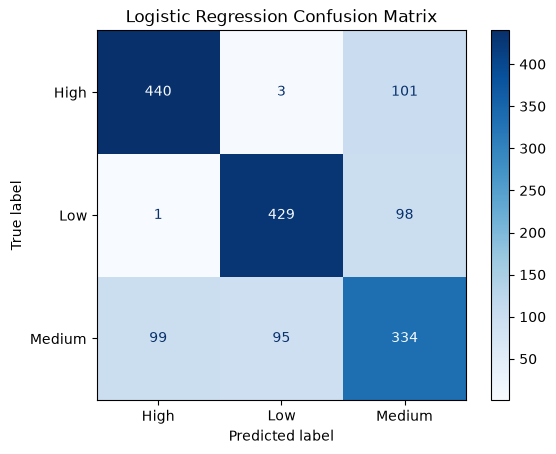

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_train,
    cv_predictions,
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

### DummyClassifier Cross-Validation

In [27]:
dummy_cv_scores = cross_val_score(
    dummy_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Dummy validation scores:", dummy_cv_scores)
print("Dummy mean validation accuracy:", dummy_cv_scores.mean())

Dummy validation scores: [0.34082397 0.33958724 0.33958724]
Dummy mean validation accuracy: 0.339999484696662


### SMHR-19 — Logistic Regression Baseline Results

**Models**
- DummyClassifier (most_frequent)
- Logistic Regression with preprocessing Pipeline

**Evaluation**
- Training set: 1,600 records
- Cross-validation: Stratified 3-fold
- Independent test set: Not used

**Results**
- DummyClassifier training accuracy: 34.00%
- DummyClassifier mean CV accuracy: 34.00%
- Logistic Regression training accuracy: 76.63%
- Logistic Regression mean CV accuracy: 75.19%

**Classification Report**
- High F1-score: 0.81
- Low F1-score: 0.81
- Medium F1-score: 0.63

**Observations**
- Logistic Regression substantially outperforms the dummy baseline.
- Training and validation accuracy are similar.
- There is no clear evidence of severe overfitting.
- The Medium category is harder to classify.
- Further model comparisons are needed to investigate underfitting.

**Limitations**
- Results are based on cross-validation, not independent test evaluation.
- The dataset's label-generation process is not independently verified.
- Predictions are for educational purposes, not clinical diagnosis.